# Planificación en la nube: FCFS, Min-Min y Max-Min

Este notebook **solo lee** `results/` y reproduce las tablas y figuras del laboratorio. Para regenerar los datos, ejecuta primero `python run_all.py` en la raíz del proyecto.

Diseño: 50 tareas, 5 VMs de 500 a 2500 MIPS, 2 escenarios y 30 semillas. Los tres algoritmos reciben el mismo dataset en cada semilla (diseño pareado).

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from scheduling import plots
from scheduling.experiment import build_summary, build_wilcoxon

RESULTS = ROOT / "results"
metrics = pd.read_csv(RESULTS / "metrics.csv")
summary = pd.read_csv(RESULTS / "summary.csv")
wilcoxon = pd.read_csv(RESULTS / "wilcoxon.csv")
print(f"{len(metrics)} filas: {metrics['scenario'].nunique()} escenarios × "
      f"{metrics['seed'].nunique()} semillas × {metrics['algorithm'].nunique()} algoritmos")

180 filas: 2 escenarios × 30 semillas × 3 algoritmos


## Comprobación de reproducibilidad

Se recalculan `summary.csv` y `wilcoxon.csv` desde `metrics.csv`. Si no coinciden, la celda falla.

In [2]:
pd.testing.assert_frame_equal(build_summary(metrics), summary)
pd.testing.assert_frame_equal(build_wilcoxon(metrics), wilcoxon)
print("summary.csv y wilcoxon.csv coinciden con metrics.csv")

summary.csv y wilcoxon.csv coinciden con metrics.csv


## Tabla resumen

Media ± desviación estándar muestral en las 30 semillas.

In [3]:
LABELS = {
    "makespan": "Makespan (s)",
    "makespan_ratio": "Makespan / cota",
    "avg_wait": "Espera prom. (s)",
    "max_wait": "Espera máx. (s)",
    "avg_turnaround": "Retorno prom. (s)",
    "arur": "ARUR",
    "di": "DI",
}
table = summary[["scenario", "algorithm"]].copy()
for metric, label in LABELS.items():
    table[label] = summary[f"{metric}_mean"].map("{:.3f}".format) + " ± " + summary[f"{metric}_std"].map("{:.3f}".format)
display(table)

,scenario,algorithm,Makespan (s),Makespan / cota,Espera prom. (s),Espera máx. (s),Retorno prom. (s),ARUR,DI
0,mixed,FCFS,213.590 ± 30.431,3.032 ± 0.434,44.060 ± 3.059,191.068 ± 28.289,53.775 ± 3.552,0.461 ± 0.052,1.788 ± 0.264
1,mixed,Min-Min,74.562 ± 4.921,1.056 ± 0.014,21.805 ± 2.016,66.331 ± 4.839,28.508 ± 2.433,0.899 ± 0.019,0.373 ± 0.061
2,mixed,Max-Min,70.887 ± 4.614,1.004 ± 0.002,42.071 ± 2.286,69.951 ± 4.494,49.122 ± 2.729,0.995 ± 0.003,0.013 ± 0.007
3,skewed,FCFS,77.911 ± 26.656,3.280 ± 1.103,14.822 ± 2.667,69.544 ± 26.264,18.161 ± 3.000,0.461 ± 0.105,1.988 ± 0.538
4,skewed,Min-Min,29.706 ± 0.737,1.252 ± 0.010,5.528 ± 0.223,20.087 ± 0.644,7.545 ± 0.267,0.679 ± 0.007,1.064 ± 0.027
5,skewed,Max-Min,23.983 ± 0.623,1.011 ± 0.003,15.893 ± 0.416,23.505 ± 0.630,18.253 ± 0.473,0.984 ± 0.004,0.040 ± 0.009


`% mejora` compara medias contra FCFS (positivo = mejor que FCFS). Una victoria es tener el menor valor de los tres algoritmos en una semilla.

In [4]:
display(summary[["scenario", "algorithm", "makespan_improvement_pct", "avg_wait_improvement_pct", "makespan_wins", "avg_wait_wins"]]
        .round(2))

,scenario,algorithm,makespan_improvement_pct,avg_wait_improvement_pct,makespan_wins,avg_wait_wins
0,mixed,FCFS,0.00,0.00,0,0
1,mixed,Min-Min,65.09,50.51,0,30
2,mixed,Max-Min,66.81,4.51,30,0
3,skewed,FCFS,0.00,0.00,0,0
4,skewed,Min-Min,61.87,62.70,0,30
5,skewed,Max-Min,69.22,-7.23,30,0


## Prueba de Wilcoxon pareada

`mean_diff` es la media de (A − B): negativa significa que A obtuvo valores menores. Con 30 pares, `p = 2/2³⁰ ≈ 1.86e-09` es el mínimo posible y aparece cuando todas las semillas van en la misma dirección (`statistic = 0`). Por eso la magnitud se lee en `mean_diff`, no en el p-valor. Los p-valores no están corregidos por comparaciones múltiples.

In [5]:
display(wilcoxon)

,scenario,metric,algorithm_a,algorithm_b,n,mean_a,mean_b,mean_diff,std_diff,statistic,p_value
0,mixed,makespan,Min-Min,Max-Min,30,74.562329,70.887397,3.674932,0.981610,0.0,1.862645e-09
1,mixed,makespan,Min-Min,FCFS,30,74.562329,213.589794,-139.027465,29.455937,0.0,1.862645e-09
2,mixed,avg_wait,Min-Min,Max-Min,30,21.804981,42.070896,-20.265915,1.262596,0.0,1.862645e-09
3,mixed,avg_wait,Min-Min,FCFS,30,21.804981,44.059789,-22.254808,2.398626,0.0,1.862645e-09
4,skewed,makespan,Min-Min,Max-Min,30,29.706354,23.983052,5.723303,0.243641,0.0,1.862645e-09
5,skewed,makespan,Min-Min,FCFS,30,29.706354,77.910939,-48.204585,26.507142,0.0,1.862645e-09
6,skewed,avg_wait,Min-Min,Max-Min,30,5.528192,15.893129,-10.364937,0.379562,0.0,1.862645e-09
7,skewed,avg_wait,Min-Min,FCFS,30,5.528192,14.822116,-9.293924,2.720236,0.0,1.862645e-09


## Figuras

### Makespan y espera promedio

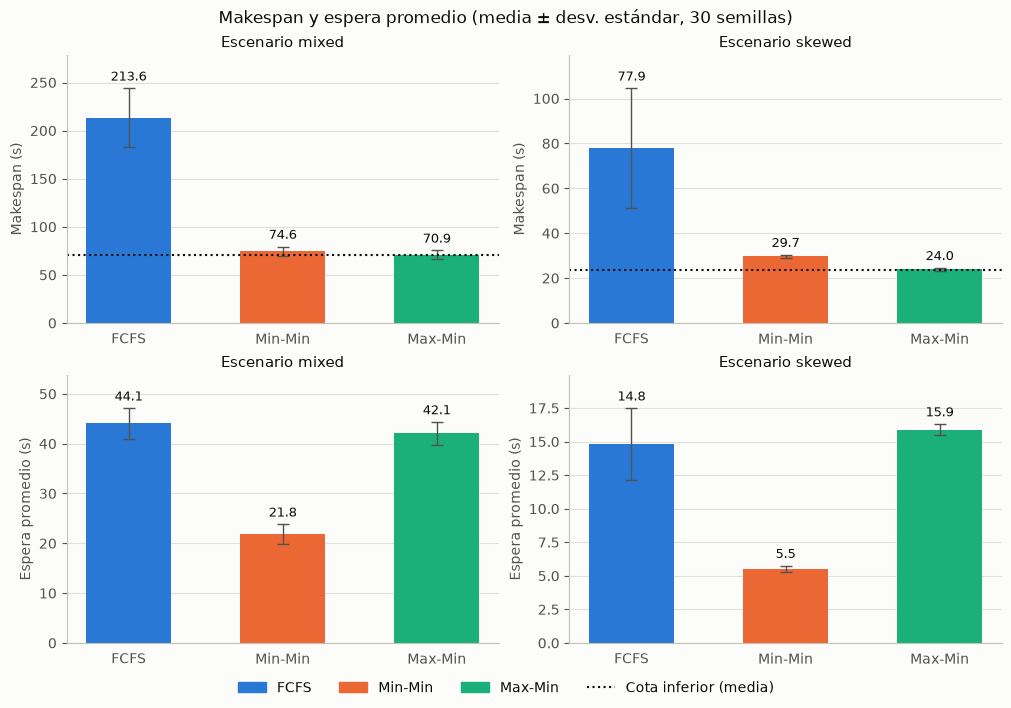

In [6]:
_ = plots.plot_makespan_wait_bars(metrics)

### Diagramas de Gantt (semilla 0)

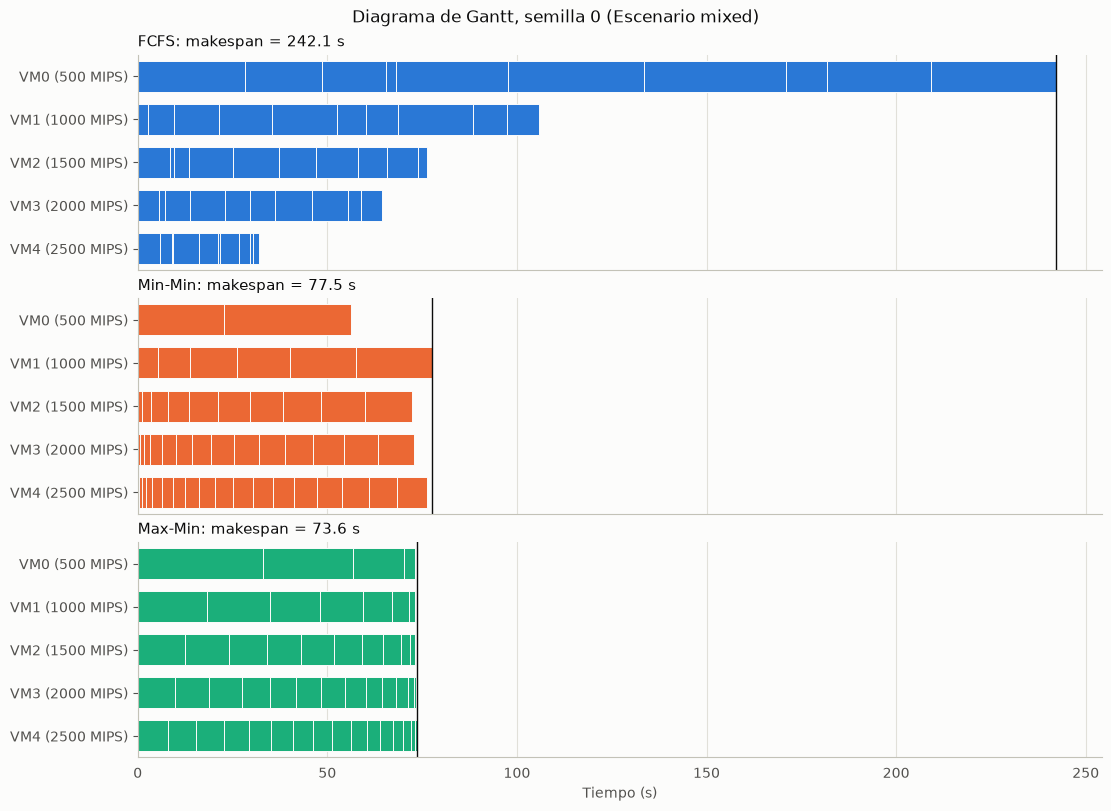

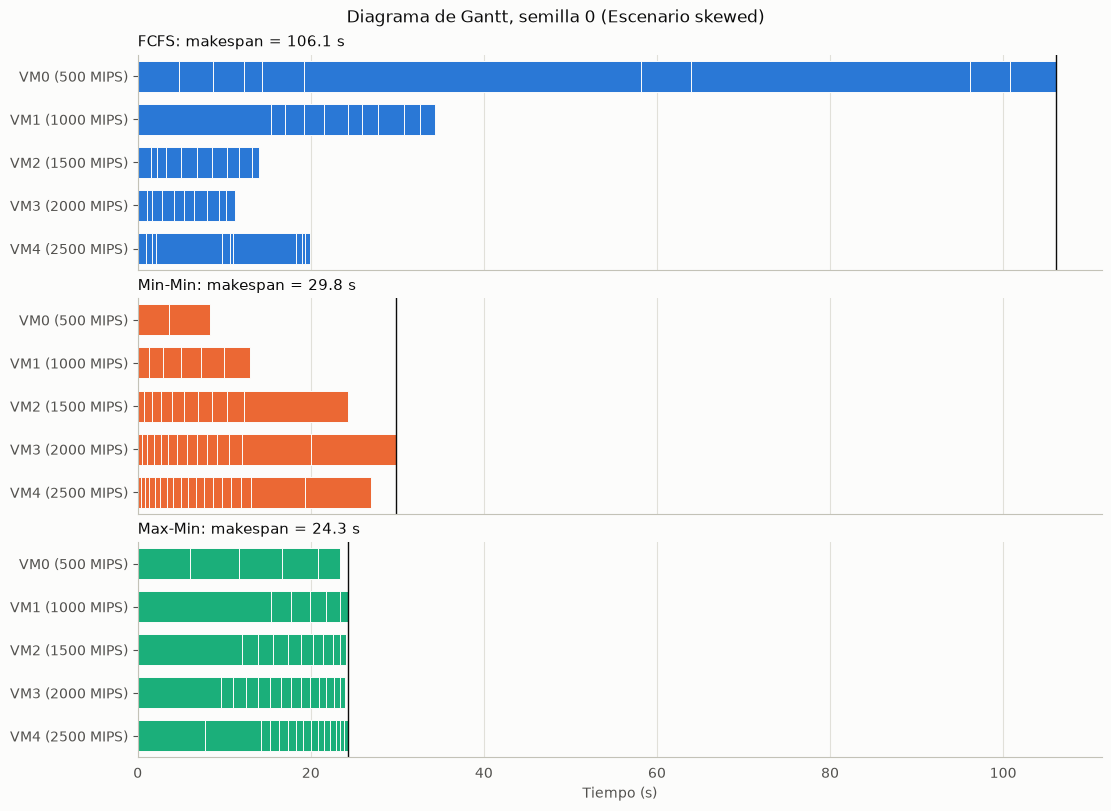

In [7]:
for scenario in ("mixed", "skewed"):
    _ = plots.plot_gantt(plots.load_gantt_assignments(RESULTS, scenario), scenario)

### Utilización por VM

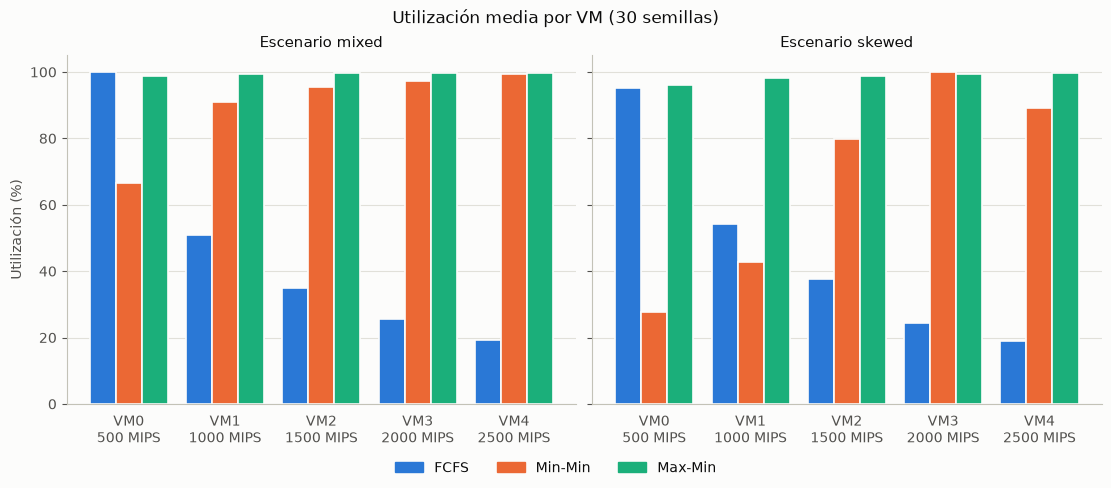

In [8]:
_ = plots.plot_vm_utilization(metrics)

### Distribución del makespan

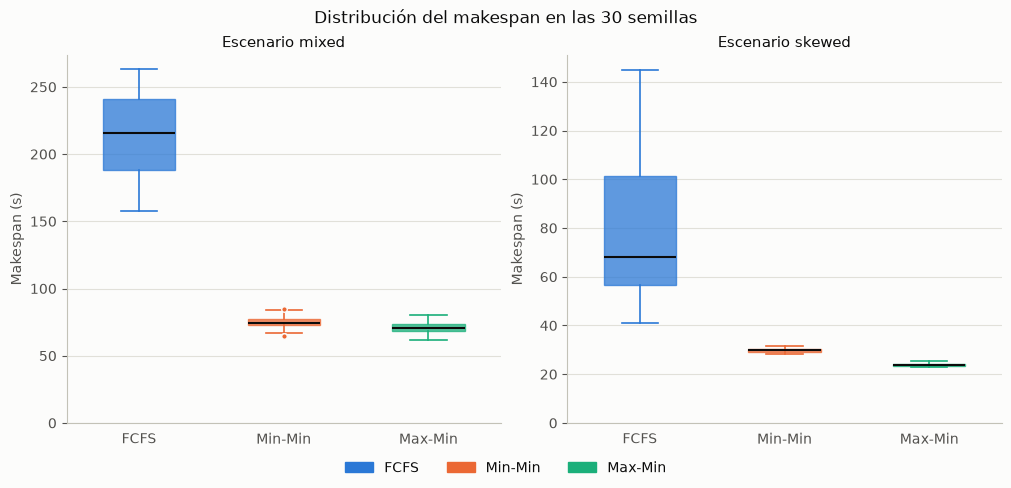

In [9]:
_ = plots.plot_makespan_boxplot(metrics)

## Respuestas a las preguntas de la guía

Las respuestas se calculan desde los resultados, no se escriben a mano.

In [10]:
for scenario, group in summary.groupby("scenario", sort=False):
    fastest = group.loc[group["makespan_mean"].idxmin()]
    best_cpu = group.loc[group["arur_mean"].idxmax()]
    balanced = group.loc[group["di_mean"].idxmin()]
    print(f"[{scenario}]")
    print(f"  ¿Cuál terminó antes? {fastest['algorithm']}: makespan medio {fastest['makespan_mean']:.2f} s, "
          f"{int(fastest['makespan_wins'])}/30 victorias")
    print(f"  ¿Cuál aprovechó mejor la CPU? {best_cpu['algorithm']}: ARUR medio {best_cpu['arur_mean']:.3f}")
    print(f"  Mejor balance: {balanced['algorithm']}: DI medio {balanced['di_mean']:.3f}")

[mixed]
  ¿Cuál terminó antes? Max-Min: makespan medio 70.89 s, 30/30 victorias
  ¿Cuál aprovechó mejor la CPU? Max-Min: ARUR medio 0.995
  Mejor balance: Max-Min: DI medio 0.013
[skewed]
  ¿Cuál terminó antes? Max-Min: makespan medio 23.98 s, 30/30 victorias
  ¿Cuál aprovechó mejor la CPU? Max-Min: ARUR medio 0.984
  Mejor balance: Max-Min: DI medio 0.040


### Dos matices que no se ven en la tabla

**VM-segundos ocupados.** ARUR mide qué fracción del tiempo está ocupada cada VM, pero no distingue una VM lenta de una rápida. `arur × makespan` da el tiempo ocupado medio por VM: un valor menor significa que el mismo trabajo se resolvió con menos VM-segundos.

In [11]:
busy = metrics.assign(busy_per_vm=metrics["arur"] * metrics["makespan"])
display(busy.pivot_table(index="scenario", columns="algorithm", values="busy_per_vm", sort=False).round(2))

algorithm,FCFS,Min-Min,Max-Min
scenario,,,
mixed,97.16,67.03,70.51
skewed,33.38,20.17,23.60


**Espera frente a FCFS, semilla por semilla.** Cuenta en cuántas de las 30 semillas cada algoritmo espera menos que FCFS. El contraste Max-Min vs FCFS no forma parte de `wilcoxon.csv`, así que aquí es solo descriptivo.

In [12]:
pivot = metrics.pivot_table(index=["scenario", "seed"], columns="algorithm", values="avg_wait", sort=False)
counts = pd.DataFrame({
    "Min-Min < FCFS": (pivot["Min-Min"] < pivot["FCFS"]).groupby("scenario", sort=False).sum(),
    "Max-Min < FCFS": (pivot["Max-Min"] < pivot["FCFS"]).groupby("scenario", sort=False).sum(),
})
display(counts)

,Min-Min < FCFS,Max-Min < FCFS
scenario,,
mixed,30,25
skewed,30,9
